In [5]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from db import Database

sys.path.append(str(Path.cwd().parent / "src"))
db = Database()
FIG_DIR = Path.cwd().parent / "figures"
FIG_DIR.mkdir(exist_ok=True)


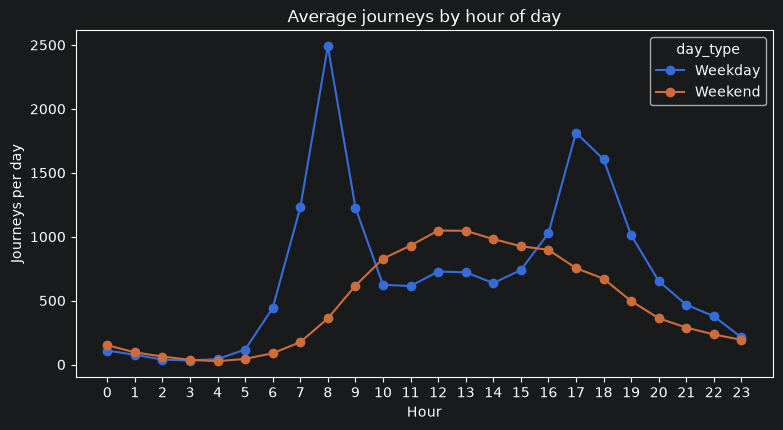

In [6]:
hourly = db.query("""
    SELECT EXTRACT(HOUR FROM start_time)::int AS hour,
           CASE WHEN EXTRACT(ISODOW FROM start_time) <= 5
                THEN 'Weekday' ELSE 'Weekend' END AS day_type,
           (COUNT(*)::float / COUNT(DISTINCT start_time::date)) AS avg_journeys
    FROM clean.journeys
    GROUP BY 1, 2
    ORDER BY 1
""")

ax = hourly.pivot(index="hour", columns="day_type", values="avg_journeys").plot(
    marker="o", figsize=(9, 4.5))
ax.set(title="Average journeys by hour of day", xlabel="Hour", ylabel="Journeys per day")
ax.set_xticks(range(0, 24))
plt.savefig(FIG_DIR / "hourly_demand.png", dpi=150, bbox_inches="tight")
plt.show()

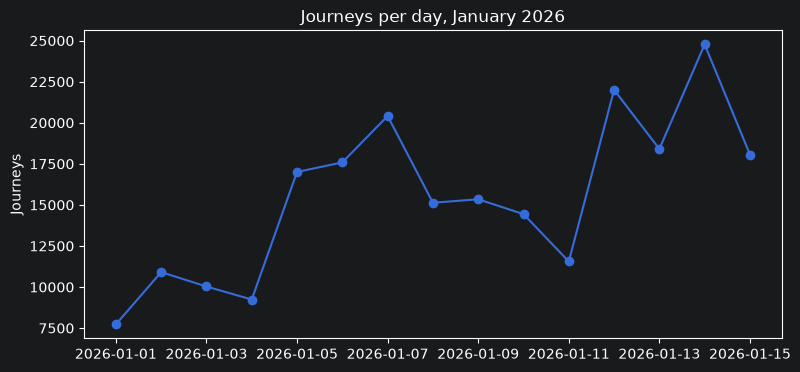

In [7]:
daily = db.query("""
    SELECT start_time::date AS day, COUNT(*) AS journeys
    FROM clean.journeys
    GROUP BY 1
    ORDER BY 1
""")

ax = daily.plot(x="day", y="journeys", marker="o", legend=False, figsize=(9, 4))
ax.set(title="Journeys per day, January 2026", xlabel="", ylabel="Journeys")
plt.savefig(FIG_DIR / "daily_journeys.png", dpi=150, bbox_inches="tight")
plt.show()

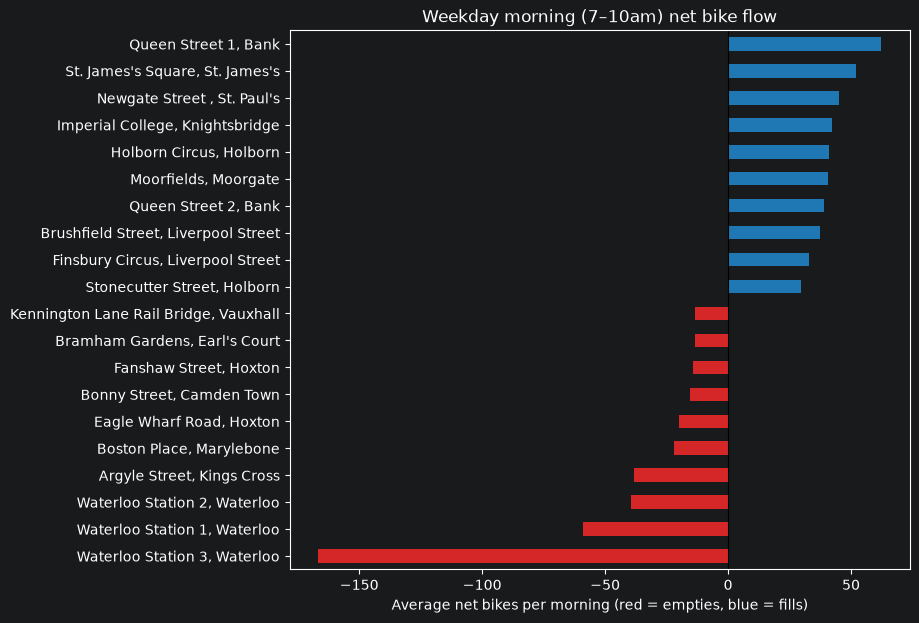

In [8]:
flow = db.query("""
    SELECT station_name, avg_net_inflow::float AS net
    FROM clean.morning_net_flow
    ORDER BY net
""")

extremes = pd.concat([flow.head(10), flow.tail(10)])
colours = ["tab:red" if v < 0 else "tab:blue" for v in extremes["net"]]

ax = extremes.plot.barh(x="station_name", y="net", color=colours,
                        legend=False, figsize=(8, 7))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Weekday morning (7–10am) net bike flow",
       xlabel="Average net bikes per morning (red = empties, blue = fills)", ylabel="")
plt.savefig(FIG_DIR / "morning_net_flow.png", dpi=150, bbox_inches="tight")
plt.show()